#Setup e Import

In [12]:
!pip install -q nltk gensim matplotlib seaborn scikit-learn scipy pandas wordcloud plotly

import nltk
import warnings
import numpy as np
import pandas as pd
import networkx as nx
import seaborn as sns
import plotly.express as px
import matplotlib.pyplot as plt
import gensim.downloader as api
import plotly.graph_objects as go

from wordcloud import WordCloud
from scipy.stats import spearmanr
from collections import defaultdict
from matplotlib.lines import Line2D
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from nltk.corpus import wordnet as wn
from scipy.spatial.distance import squareform
from scipy.cluster.hierarchy import dendrogram, linkage
from scipy.cluster.hierarchy import dendrogram, linkage

nltk.download('wordnet', quiet=True)
nltk.download('omw-1.4', quiet=True)

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

#Caricamento GloVe

In [4]:
model = api.load('glove-wiki-gigaword-100')

# Ottiene il vettore embedding di una parola
def get_vector(word):
    return model[word] if word in model else None

# Calcola la cosine similarity tra due vettori
def cosine_similarity(v1, v2):
    if v1 is None or v2 is None:
        return None
    norm_product = np.linalg.norm(v1) * np.linalg.norm(v2)
    if norm_product == 0:
        return 0.0
    return float(np.dot(v1, v2) / norm_product)

[==================================================] 100.0% 128.1/128.1MB downloaded


#Definizioni WordNet

In [5]:
target_definitions = [
    {
        'word': 'dog',
        'synset': 'dog.n.01',
        'description': 'Animale domestico carnivoro'
    },
    {
        'word': 'bank',
        'synset': 'bank.n.01',
        'description': 'Riva di un fiume o lago'
    },
    {
        'word': 'bank',
        'synset': 'bank.n.02',
        'description': 'Istituzione finanziaria'
    },
    {
        'word': 'bright',
        'synset': 'bright.a.01',
        'description': 'Che emette luce intensa'
    },
    {
        'word': 'bright',
        'synset': 'bright.s.03',
        'description': 'Persona intelligente'
    },
    {
        'word': 'run',
        'synset': 'run.v.01',
        'description': 'Muoversi velocemente con le gambe'
    },
    {
        'word': 'run',
        'synset': 'run.v.13',
        'description': 'Far funzionare una macchina'
    }
]

for i, tdef in enumerate(target_definitions, 1):
    synset = wn.synset(tdef['synset'])

    print(f"\n{tdef['word']}: {tdef['synset']}")
    print(f"    WordNet: {synset.definition()}")
    print(f"    Italiano: {tdef['description']}")
    print(f"    Esempi: {synset.examples()[:2] if synset.examples() else 'Nessuno'}")

    lemmas = [lemma.name().replace('_', ' ') for lemma in synset.lemmas()]
    print(f"    Sinonimi: {', '.join(lemmas)}")


dog: dog.n.01
    WordNet: a member of the genus Canis (probably descended from the common wolf) that has been domesticated by man since prehistoric times; occurs in many breeds
    Italiano: Animale domestico carnivoro
    Esempi: ['the dog barked all night']
    Sinonimi: dog, domestic dog, Canis familiaris

bank: bank.n.01
    WordNet: sloping land (especially the slope beside a body of water)
    Italiano: Riva di un fiume o lago
    Esempi: ['they pulled the canoe up on the bank', 'he sat on the bank of the river and watched the currents']
    Sinonimi: bank

bank: bank.n.02
    WordNet: a financial institution that accepts deposits and channels the money into lending activities
    Italiano: Istituzione finanziaria
    Esempi: ['he cashed a check at the bank', 'that bank holds the mortgage on my home']
    Sinonimi: depository financial institution, bank, banking concern, banking company

bright: bright.a.01
    WordNet: emitting or reflecting light readily or in large amounts
 

#Funzioni per strazioni sinonimi

In [6]:
def extract_synonyms_from_synset(synset_name):
    synset = wn.synset(synset_name)
    synonyms = []

    # Sinonimi diretti dal synset
    for lemma in synset.lemmas():
        word = lemma.name().replace('_', ' ').lower()
        synonyms.append(word)

    # Aggiungi anche iponimi diretti (parole più specifiche)
    for hypo in synset.hyponyms():
        for lemma in hypo.lemmas()[:2]:
            word = lemma.name().replace('_', ' ').lower()
            if word not in synonyms:
                synonyms.append(word)

    return list(set(synonyms))


# Trova parole vicine negli embeddings e classifica come sinonimi confermati (in WordNet) o potenziali nuovi sinonimi (non in WordNet)
def find_embedding_neighbors(word, target_synonyms, topn=100):
    if word not in model:
        return [], [], None

    similar_words = model.most_similar(word, topn=topn)

    wn_sims = []
    word_vec = get_vector(word)
    for syn in target_synonyms:
        if syn in model and syn != word:
            syn_vec = get_vector(syn)
            sim = cosine_similarity(word_vec, syn_vec)
            if sim is not None:
                wn_sims.append(sim)

    threshold = np.mean(wn_sims) if wn_sims else 0.5
    min_threshold = min(wn_sims) * 0.85 if wn_sims else 0.4

    confirmed = []
    potential_new = []

    for sim_word, similarity in similar_words:
        if sim_word in target_synonyms:
            confirmed.append((sim_word, similarity, 'confirmed'))
        elif similarity >= min_threshold:
            potential_new.append((sim_word, similarity, 'potential'))

    return confirmed, potential_new, threshold

# Analisi Embedding vs Wordnet

In [7]:
results = []

for tdef in target_definitions:
    synset_name = tdef['synset']
    word = tdef['word']
    print(f"\n", "-"*80)
    print(f"\nAnalizzando: '{word}' ({synset_name})")
    print(f"   {wn.synset(synset_name).definition()}")

    # Estrai sinonimi WordNet
    wn_synonyms = extract_synonyms_from_synset(synset_name)
    wn_synonyms_in_glove = [s for s in wn_synonyms if s in model]

    print(f"Sinonimi WordNet trovati: {len(wn_synonyms)}")
    print(f"   Presenti in GloVe: {len(wn_synonyms_in_glove)}")
    print(f"   ->  {', '.join(wn_synonyms_in_glove[:10])}\n")

    # Calcola similarità con sinonimi
    word_vec = get_vector(word)
    syn_similarities = []

    if word_vec is not None:
        print("Similarità con sinonimi WordNet:")
        for syn in wn_synonyms_in_glove[:15]:
            syn_vec = get_vector(syn)
            sim = cosine_similarity(word_vec, syn_vec)
            if sim is not None:
                syn_similarities.append((syn, sim))

        syn_similarities.sort(key=lambda x: x[1], reverse=True)
        for syn, sim in syn_similarities[:8]:
            print(f"   - {syn:20s} {sim:.4f}")

    # Trova potenziali nuovi sinonimi
    confirmed, potential_new, threshold = find_embedding_neighbors(
        word, wn_synonyms, topn=150
    )

    # print(f"\nSoglia similarità (basata su sinonimi WN): {threshold:.4f}")
    print(f"\n Potenziali nuovi sinonimi (non in WordNet, ma simili in GloVe):")
    print(f"   Trovati: {len(potential_new)}")

    for new_word, sim, _ in potential_new[:15]:
        print(f"   - {new_word:25s} {sim:.4f}")

    results.append({
        'word': word,
        'synset': synset_name,
        'definition': wn.synset(synset_name).definition(),
        'wn_synonyms': wn_synonyms_in_glove,
        'syn_similarities': syn_similarities,
        'potential_new': potential_new,
        'confirmed': confirmed,
        'threshold': threshold
    })


 --------------------------------------------------------------------------------

Analizzando: 'dog' (dog.n.01)
   a member of the genus Canis (probably descended from the common wolf) that has been domesticated by man since prehistoric times; occurs in many breeds
Sinonimi WordNet trovati: 30
   Presenti in GloVe: 17
   ->  poodle, leonberg, newfoundland, toy, basenji, dalmatian, puppy, griffon, dog, lapdog

Similarità con sinonimi WordNet:
   - dog                  1.0000
   - puppy                0.7236
   - toy                  0.5283
   - poodle               0.5256
   - pug                  0.4700
   - pooch                0.4335
   - dalmatian            0.3291
   - doggie               0.2977

 Potenziali nuovi sinonimi (non in WordNet, ma simili in GloVe):
   Trovati: 147
   - cat                       0.8798
   - dogs                      0.8344
   - pet                       0.7450
   - horse                     0.7110
   - animal                    0.6817
   - pig        

#Network Graph

In [9]:
def create_interactive_network(result_item, max_new=20):

    word = result_item['word']
    wn_syns = result_item['wn_synonyms'][:10]
    potential = result_item['potential_new'][:max_new]

    # Due grafi: uno per sim >= 0, uno per sim < 0
    G_pos = nx.Graph()
    G_neg = nx.Graph()

    # Nodo centrale
    for G in [G_pos, G_neg]:
        G.add_node(word, node_type='central', size=50)

    # sinonimi WordNet
    for syn, sim in result_item['syn_similarities'][:10]:
        target_graph = G_pos if sim >= 0 else G_neg
        target_graph.add_node(syn, node_type='wordnet', size=25)
        target_graph.add_edge(word, syn, weight=abs(sim), edge_type='wordnet')

    # potenziali nuovi sinonimi
    for new_word, sim, _ in potential:
        target_graph = G_pos if sim >= 0 else G_neg
        target_graph.add_node(new_word, node_type='potential', size=20)
        target_graph.add_edge(word, new_word, weight=abs(sim), edge_type='potential')

    def make_fig(G, positive=True):
        pos = nx.spring_layout(G, k=2, iterations=50, seed=42)
        edge_traces = []

        # Edge WordNet
        for edge in G.edges():
            color = 'rgba(100, 149, 237, 0.8)' if positive else 'rgba(169,169,169,0.5)'
            width_mult = 3 if positive else 2
            if G.edges[edge].get('edge_type') == 'wordnet':
                x0, y0 = pos[edge[0]]
                x1, y1 = pos[edge[1]]
                weight = G.edges[edge]['weight']
                edge_traces.append(go.Scatter(
                    x=[x0, x1, None], y=[y0, y1, None],
                    mode='lines',
                    line=dict(width=weight*width_mult, color=color),
                    hoverinfo='none',
                    showlegend=False
                ))

        # Edge Potenziali
        for edge in G.edges():
            color = 'rgba(255, 140, 0, 0.6)' if positive else 'rgba(169,169,169,0.4)'
            width_mult = 2 if positive else 1.5
            if G.edges[edge].get('edge_type') == 'potential':
                x0, y0 = pos[edge[0]]
                x1, y1 = pos[edge[1]]
                weight = G.edges[edge]['weight']
                edge_traces.append(go.Scatter(
                    x=[x0, x1, None], y=[y0, y1, None],
                    mode='lines',
                    line=dict(width=weight*width_mult, color=color),
                    hoverinfo='none',
                    showlegend=False
                ))

        # Nodi
        node_traces = {'central': [], 'wordnet': [], 'potential': []}
        for node in G.nodes():
            x, y = pos[node]
            node_type = G.nodes[node]['node_type']
            size = G.nodes[node]['size']

            color_map = {
                'central': 'rgb(255, 0, 0)',
                'wordnet': 'rgb(100, 149, 237)' if positive else 'rgb(169,169,169)',
                'potential': 'rgb(255, 140, 0)' if positive else 'rgb(200,200,200)'
            }

            node_traces[node_type].append(go.Scatter(
                x=[x], y=[y],
                mode='markers+text',
                marker=dict(size=size, color=color_map[node_type], line=dict(width=2, color='white')),
                text=[node],
                textposition="top center",
                textfont=dict(size=10, color='black'),
                hovertext=f"{node}<br>Type: {node_type}",
                hoverinfo='text',
                showlegend=True if len(node_traces[node_type]) == 0 else False,
                name=node_type.upper()
            ))

        fig = go.Figure(data=edge_traces + node_traces['wordnet'] + node_traces['potential'] + node_traces['central'])
        label = "Positive" if positive else "Negative (Distance)"
        # color_note = "" if positive else "Connessioni con similarità negativa (lontananza semantica)</sub>"

        fig.update_layout(
            title=dict(
                text=f"Semantic Network ({label}): '{word}' ({result_item['synset']})<br><sub>{result_item['definition']}</sub>",
                font=dict(size=20)
            ),
            showlegend=True,
            hovermode='closest',
            margin=dict(b=0, l=0, r=0, t=120),
            xaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
            yaxis=dict(showgrid=False, zeroline=False, showticklabels=False),
            plot_bgcolor='rgba(240, 240, 240, 0.9)',
            width=1000,
            height=800
        )
        return fig

    fig_pos = make_fig(G_pos, positive=True)
    fig_neg = make_fig(G_neg, positive=False)

    return fig_pos, fig_neg


for result in results[:4]:
    fig_pos, fig_neg = create_interactive_network(result, max_new=15)
    fig_pos.show()
    fig_neg.show()


#Heatmap con Clustering Gerarchico

VISUALIZZAZIONE SIMILARITÀ CON TARGET


dog → dog.n.01
a member of the genus Canis (probably descended from the common wolf) that has been domesticated by man since prehistoric times; occurs in many breeds



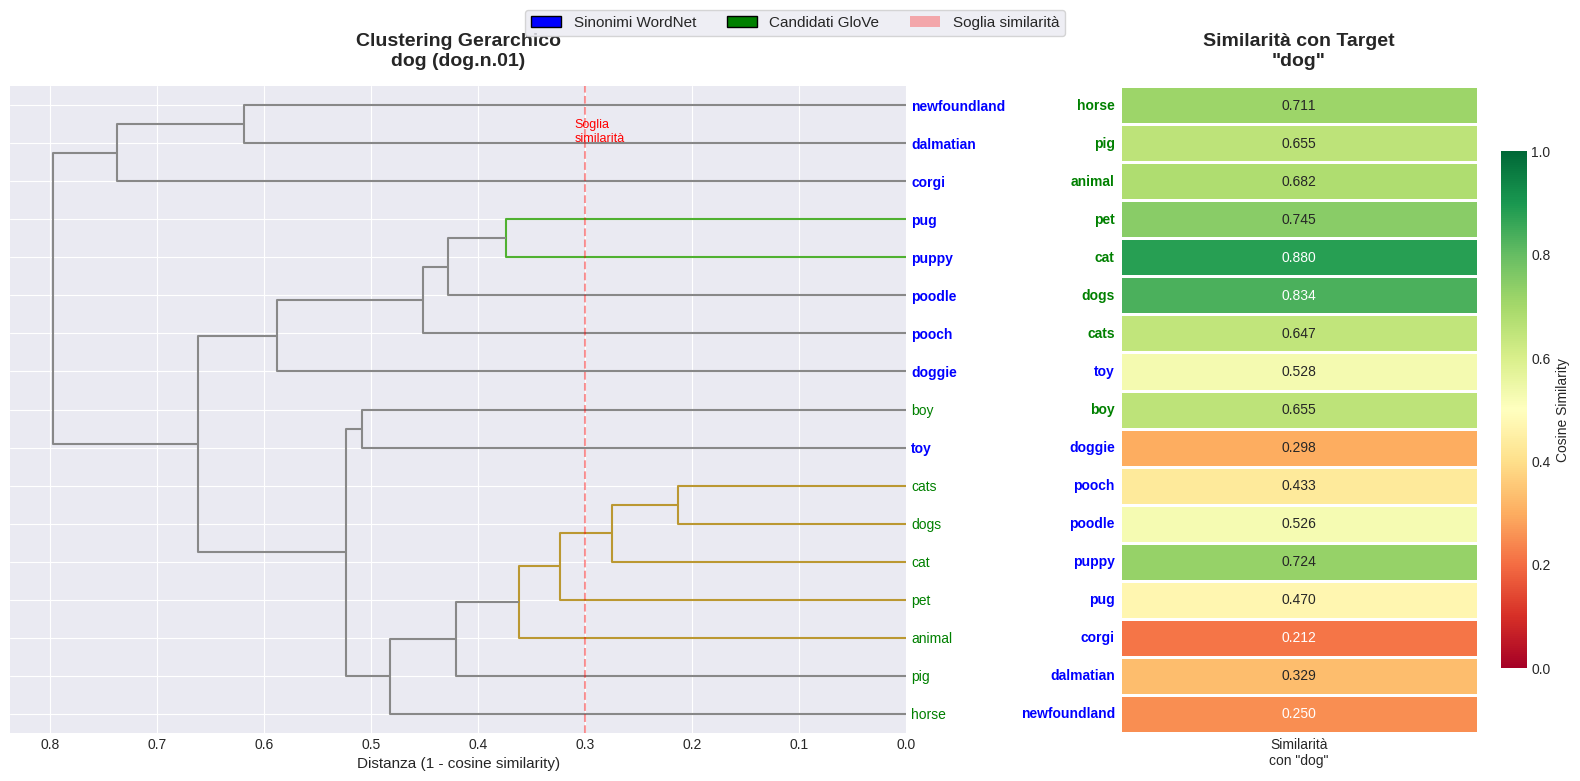

'dog' (dog.n.01):
Sinonimi WordNet: 9
Candidati GloVe: 8
Top-3 più simili:
      cat                  0.880 [NEW]
      dogs                 0.834 [NEW]
      pet                  0.745 [NEW]


bank → bank.n.01
sloping land (especially the slope beside a body of water)



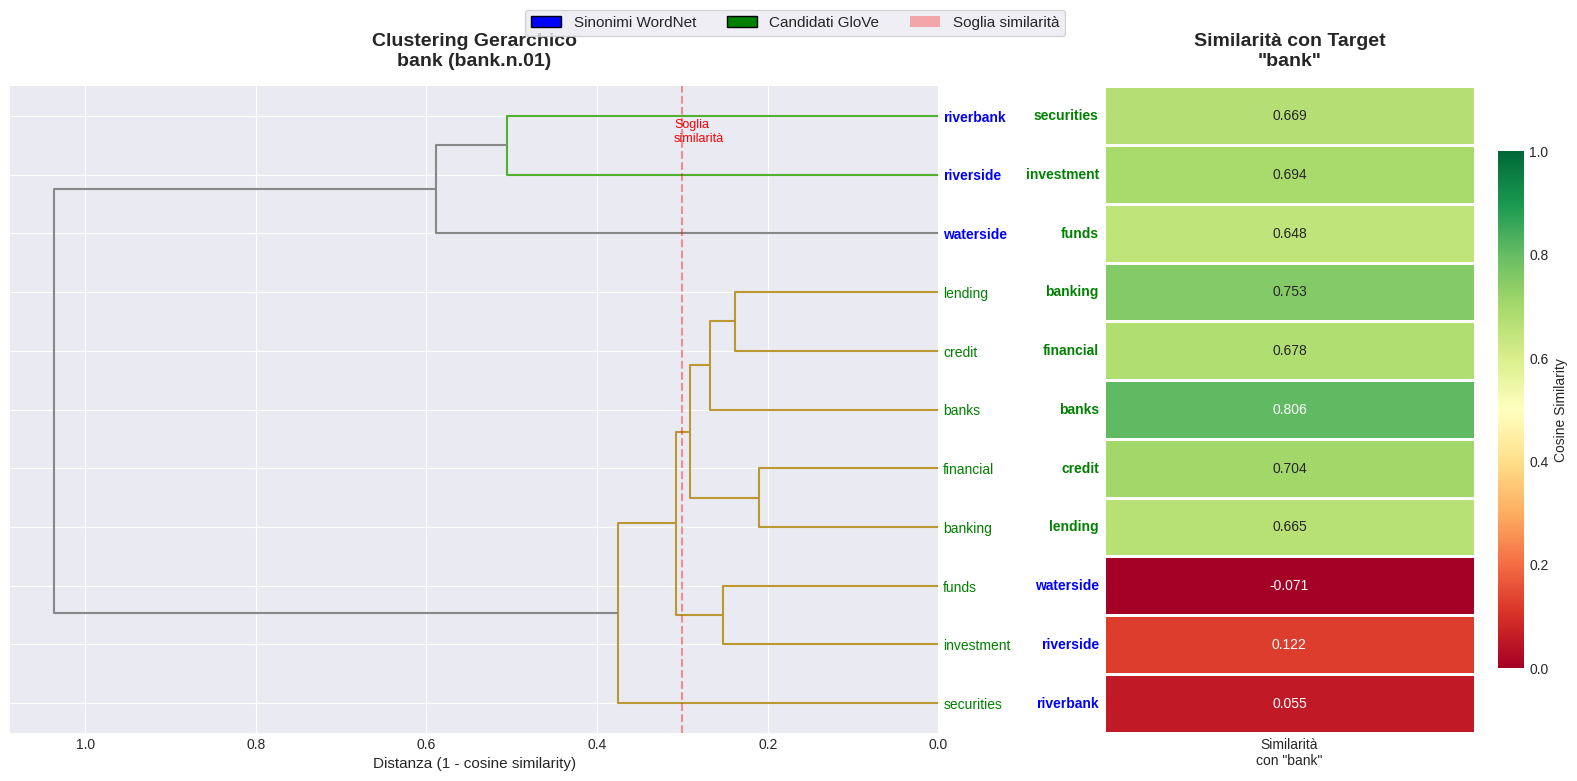

'bank' (bank.n.01):
Sinonimi WordNet: 3
Candidati GloVe: 8
Top-3 più simili:
      banks                0.806 [NEW]
      banking              0.753 [NEW]
      credit               0.704 [NEW]


bank → bank.n.02
a financial institution that accepts deposits and channels the money into lending activities



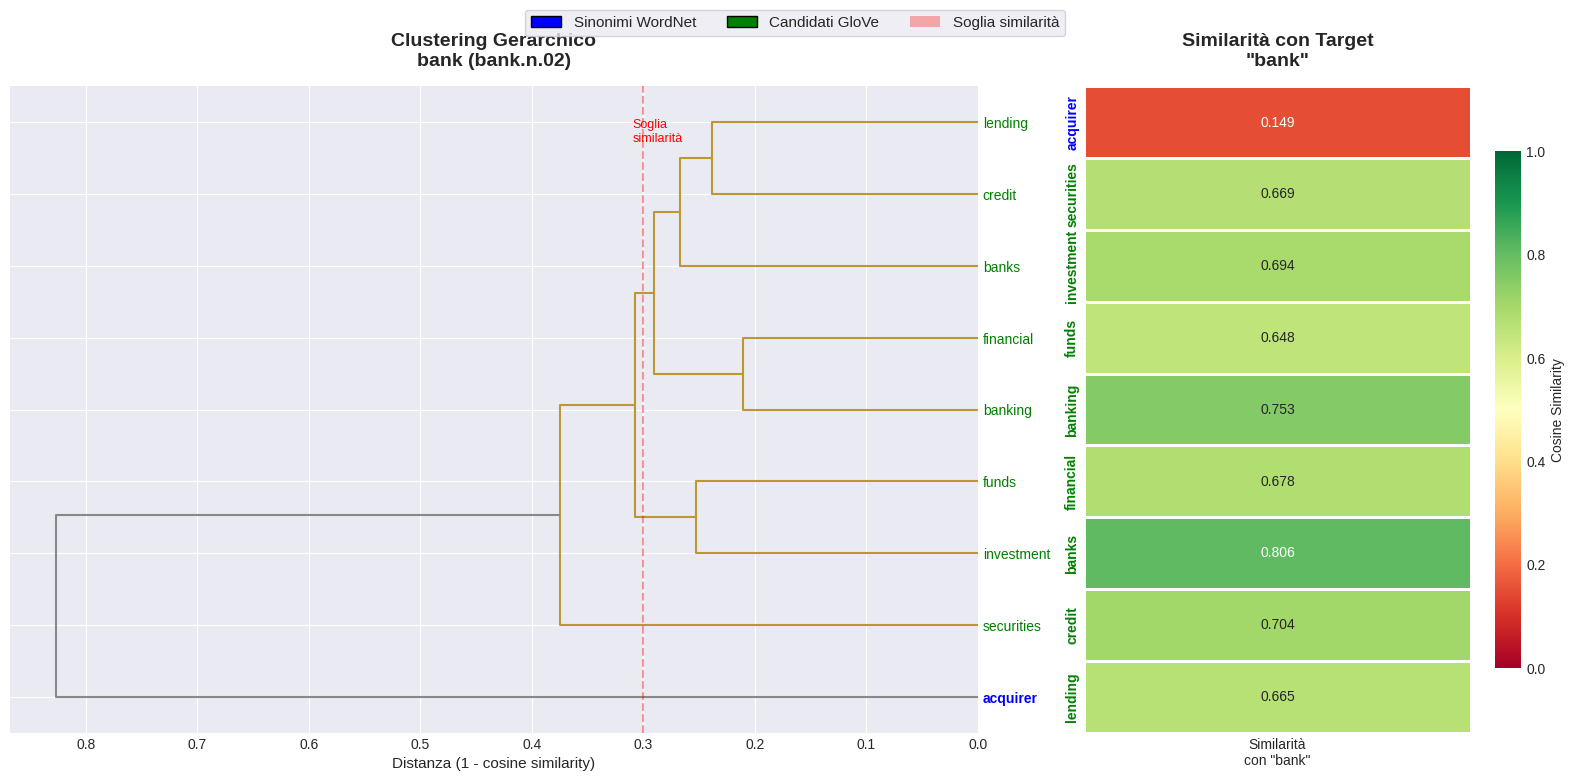

'bank' (bank.n.02):
Sinonimi WordNet: 1
Candidati GloVe: 8
Top-3 più simili:
      banks                0.806 [NEW]
      banking              0.753 [NEW]
      credit               0.704 [NEW]


bright → bright.a.01
emitting or reflecting light readily or in large amounts



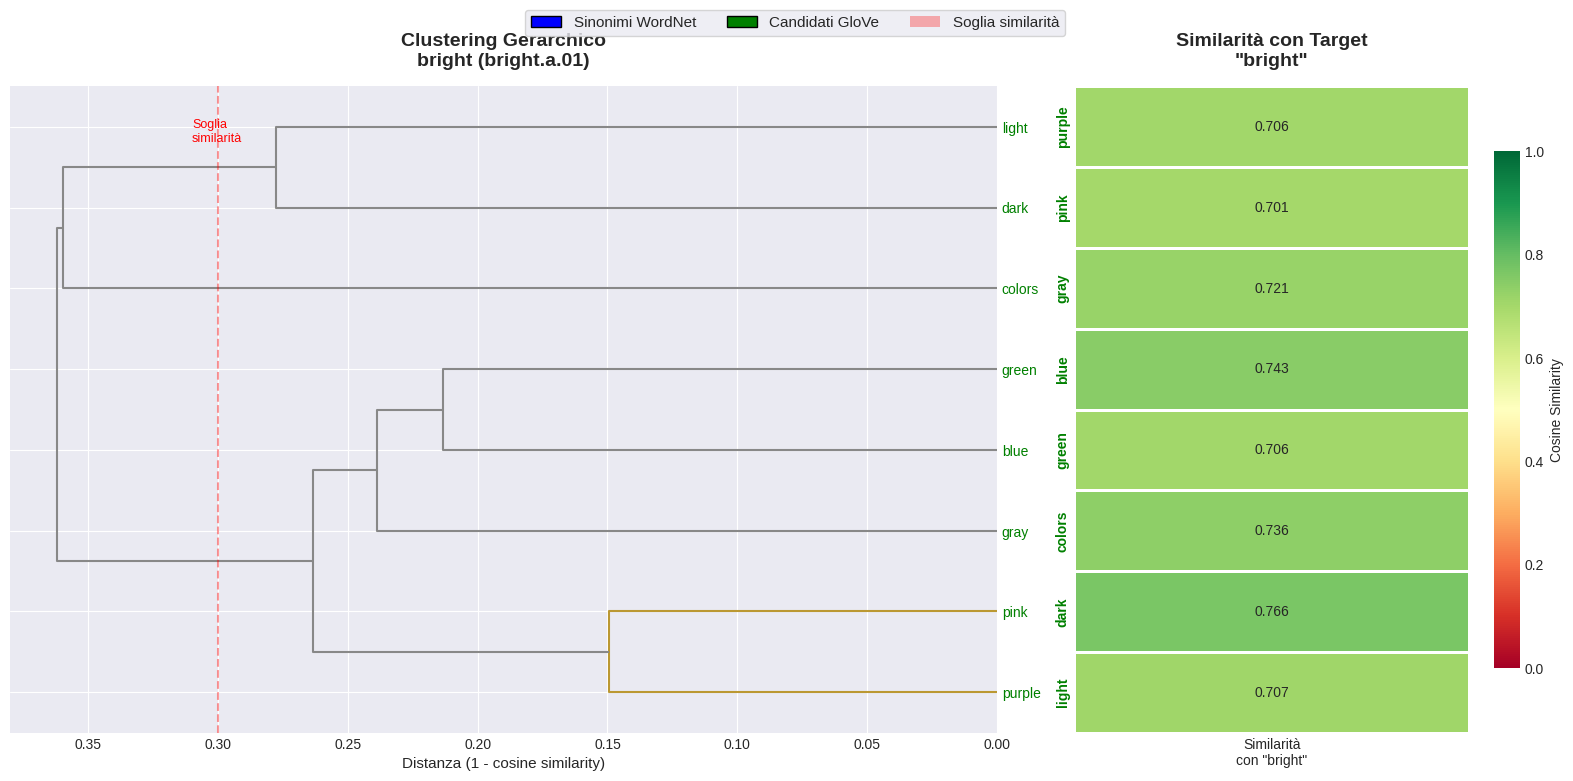

'bright' (bright.a.01):
Sinonimi WordNet: 0
Candidati GloVe: 8
Top-3 più simili:
      dark                 0.766 [NEW]
      blue                 0.743 [NEW]
      colors               0.736 [NEW]


bright → bright.s.03
characterized by quickness and ease in learning



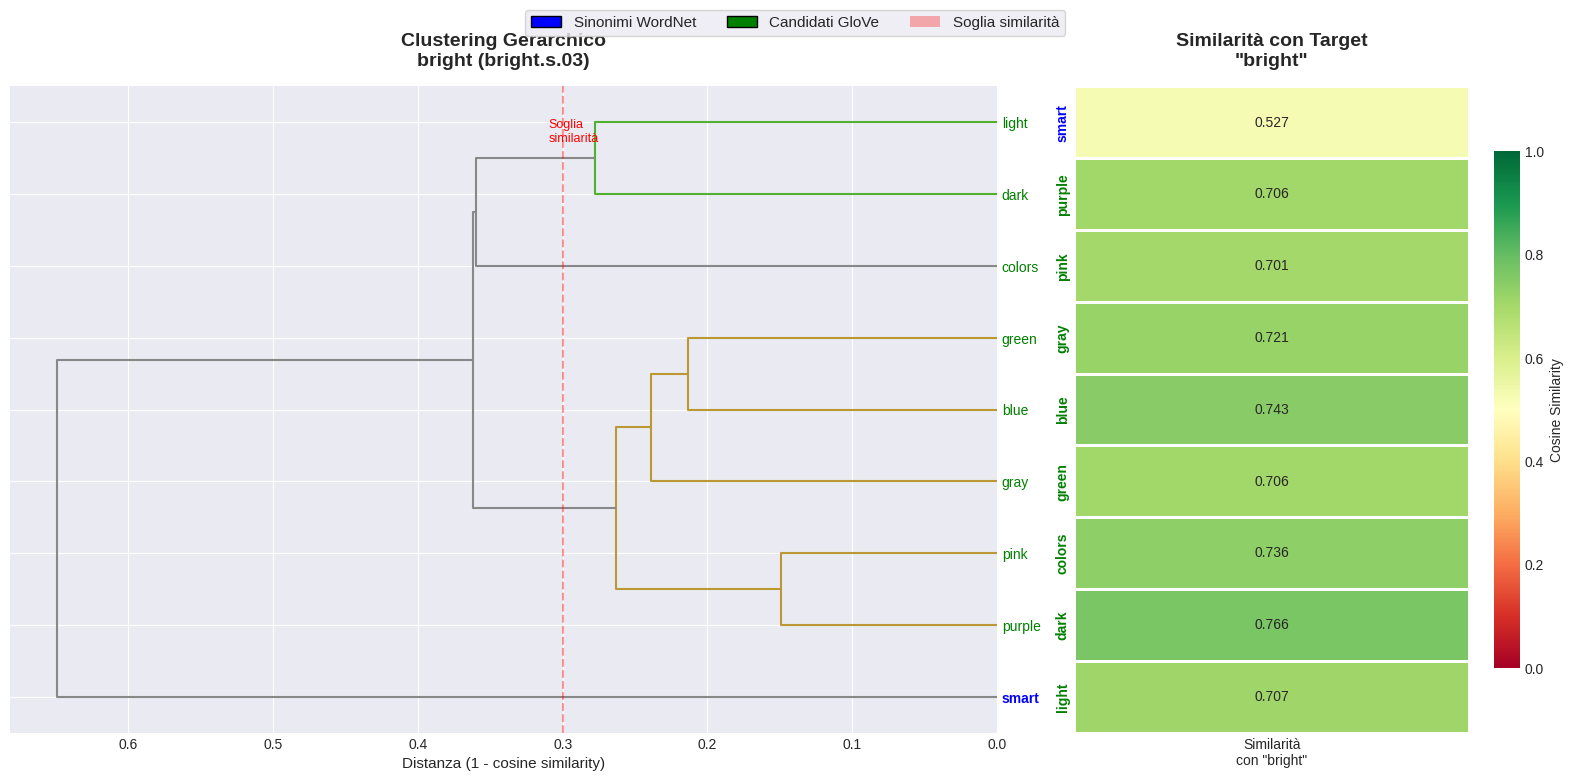

'bright' (bright.s.03):
Sinonimi WordNet: 1
Candidati GloVe: 8
Top-3 più simili:
      dark                 0.766 [NEW]
      blue                 0.743 [NEW]
      colors               0.736 [NEW]


run → run.v.01
move fast by using one's feet, with one foot off the ground at any given time



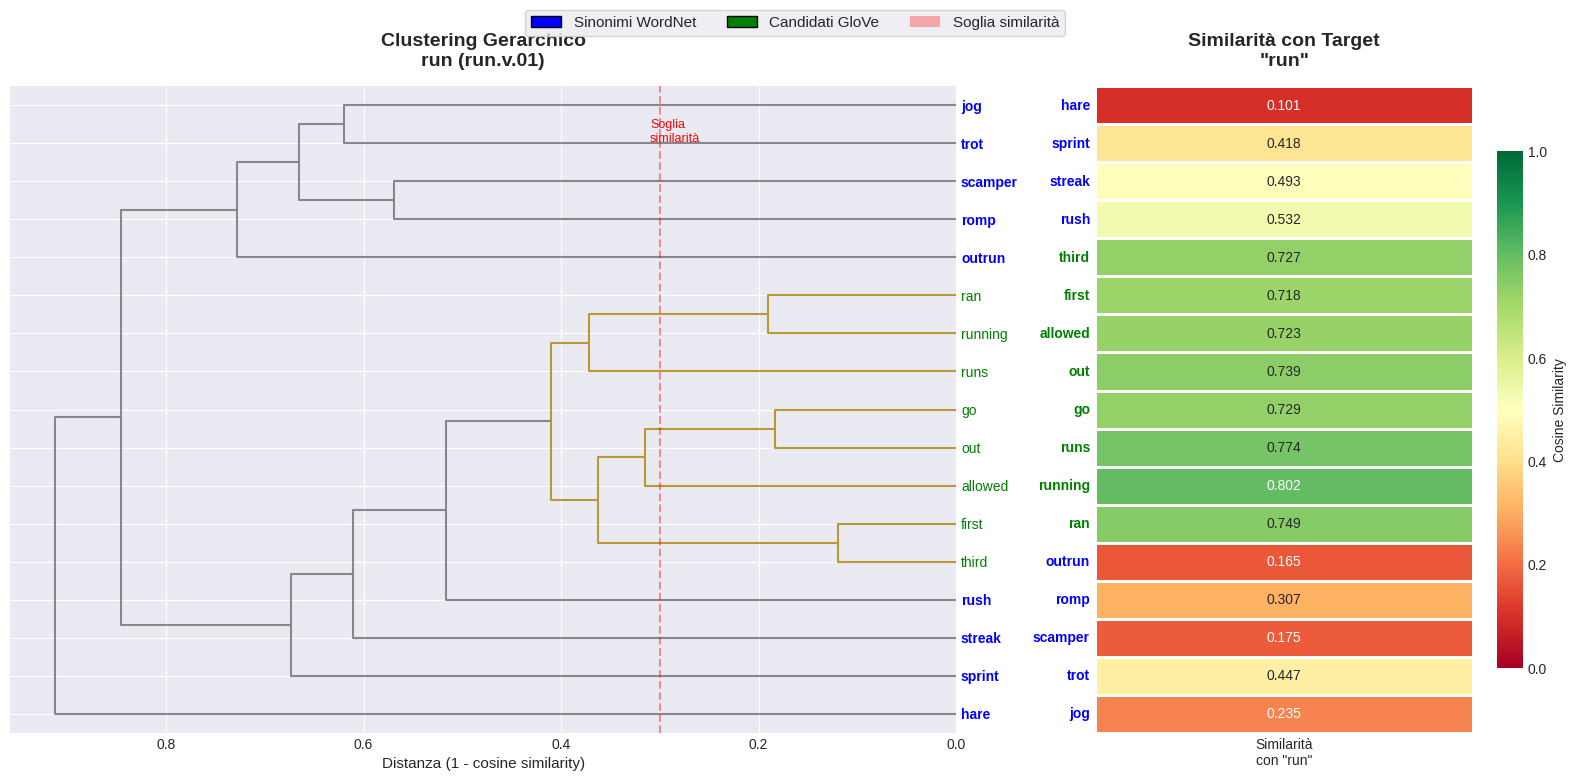

'run' (run.v.01):
Sinonimi WordNet: 9
Candidati GloVe: 8
Top-3 più simili:
      running              0.802 [NEW]
      runs                 0.774 [NEW]
      ran                  0.749 [NEW]


run → run.v.13
be operating, running or functioning



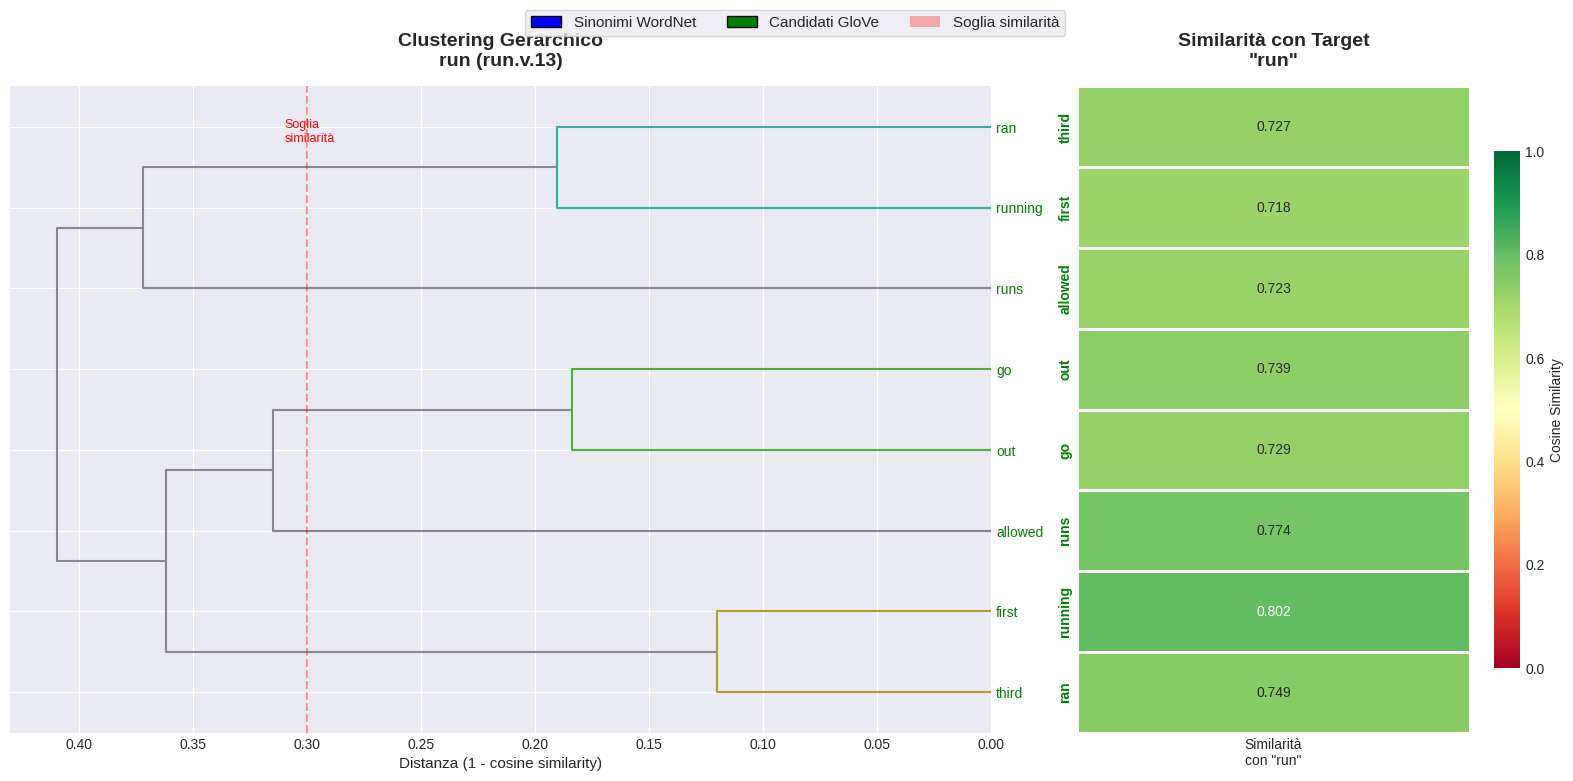

'run' (run.v.13):
Sinonimi WordNet: 0
Candidati GloVe: 8
Top-3 più simili:
      running              0.802 [NEW]
      runs                 0.774 [NEW]
      ran                  0.749 [NEW]



In [10]:
def create_target_focused_visualization(result_item, max_wn_synonyms=10, max_new_candidates=8):
    word = result_item['word']
    synset = result_item['synset']

    words_list = []
    word_types = {}
    similarities_to_target = {}

    # Target
    word_vec = get_vector(word)
    if word_vec is None:
        print(f"'{word}' non trovato in GloVe, skip")
        return

    # Sinonimi WordNet
    for syn, sim in result_item['syn_similarities'][:max_wn_synonyms]:
        if syn in model and syn != word:
            words_list.append(syn)
            word_types[syn] = 'WN'
            similarities_to_target[syn] = sim

    # Candidati nuovi
    for new_word, sim, _ in result_item['potential_new'][:max_new_candidates]:
        if new_word in model and new_word != word:
            words_list.append(new_word)
            word_types[new_word] = 'NEW'
            similarities_to_target[new_word] = sim

    if len(words_list) < 2:
        print(f"Troppo poche parole per '{word}', skip")
        return

    # Calcola matrice di similarità completa (per clustering)
    n = len(words_list)
    full_sim_matrix = np.zeros((n, n))

    for i, w1 in enumerate(words_list):
        for j, w2 in enumerate(words_list):
            v1, v2 = get_vector(w1), get_vector(w2)
            if v1 is not None and v2 is not None:
                full_sim_matrix[i, j] = cosine_similarity(v1, v2)

    # Clustering gerarchico
    dist_matrix = 1 - full_sim_matrix
    np.fill_diagonal(dist_matrix, 0)
    dist_matrix = np.clip(dist_matrix, 0, 2)
    condensed_dist = squareform(dist_matrix, checks=False)
    linkage_matrix = linkage(condensed_dist, method='average')

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, max(8, len(words_list)*0.4)),
                                     gridspec_kw={'width_ratios': [2, 1]})

    dendro = dendrogram(linkage_matrix, orientation='left',
                        labels=words_list, ax=ax1,
                        color_threshold=0.5*max(linkage_matrix[:,2]),
                        above_threshold_color='#888888')

    ax1.set_title(f'Clustering Gerarchico\n{word} ({synset})',
                  fontsize=14, weight='bold', pad=15)
    ax1.set_xlabel('Distanza (1 - cosine similarity)', fontsize=11)
    ax1.tick_params(axis='y', labelsize=10)

    for label in ax1.get_yticklabels():
        text = label.get_text()
        if word_types.get(text) == 'WN':
            label.set_color('blue')
            label.set_weight('bold')
        elif word_types.get(text) == 'NEW':
            label.set_color('green')

    # Linea di riferimento
    ax1.axvline(x=0.3, color='red', linestyle='--', alpha=0.4, linewidth=1.5)
    ax1.text(0.31, ax1.get_ylim()[1]*0.95, 'Soglia\nsimilarità',
             fontsize=9, color='red', va='top')

    # HEATMAP
    idx = dendro['leaves']
    words_ordered = [words_list[i] for i in idx]

    # Crea array di similarità
    target_sims = np.array([[similarities_to_target[w]] for w in words_ordered])

    sns.heatmap(target_sims,
                yticklabels=words_ordered,
                xticklabels=[f'Similarità\ncon "{word}"'],
                annot=True, fmt='.3f',
                cmap='RdYlGn', vmin=0, vmax=1.0,
                center=0.5,
                ax=ax2,
                cbar_kws={'label': 'Cosine Similarity', 'shrink': 0.8},
                linewidths=1, linecolor='white')

    ax2.set_title(f'Similarità con Target\n"{word}"',
                  fontsize=14, weight='bold', pad=15)
    ax2.set_ylabel('')

    for label in ax2.get_yticklabels():
        text = label.get_text()
        if word_types.get(text) == 'WN':
            label.set_color('blue')
            label.set_weight('bold')
        elif word_types.get(text) == 'NEW':
            label.set_color('green')
            label.set_weight('bold')

    # Legenda
    from matplotlib.patches import Patch
    legend_elements = [
        Patch(facecolor='blue', edgecolor='black', label='Sinonimi WordNet'),
        Patch(facecolor='green', edgecolor='black', label='Candidati GloVe'),
        Patch(facecolor='red', alpha=0.3, label='Soglia similarità')
    ]
    fig.legend(handles=legend_elements, loc='upper center',
               bbox_to_anchor=(0.5, 0.98), ncol=3, fontsize=11, frameon=True)

    plt.tight_layout(rect=[0, 0, 1, 0.96])
    plt.show()

    # Statistiche
    wn_count = sum(1 for t in word_types.values() if t == 'WN')
    new_count = sum(1 for t in word_types.values() if t == 'NEW')

    print(f"'{word}' ({synset}):")
    print(f"Sinonimi WordNet: {wn_count}")
    print(f"Candidati GloVe: {new_count}")

    # Top 3 più simili
    top_similar = sorted(similarities_to_target.items(), key=lambda x: x[1], reverse=True)[:3]
    print(f"Top-3 più simili:")
    for w, sim in top_similar:
        tipo = "WN" if word_types[w] == 'WN' else "NEW"
        print(f"      {w:20s} {sim:.3f} [{tipo}]")
    print()


for result in results:
    print(f"\n{result['word']} → {result['synset']}")
    print(f"{result['definition']}\n")
    create_target_focused_visualization(result, max_wn_synonyms=10, max_new_candidates=8)

#t-SNE multiclasse

In [1]:

def create_tsne_visualization(results_list, perplexity=30):

    all_words = {}

    for result in results_list:
        word = result['word']
        synset = result['synset']

        # Parola centrale
        all_words[word] = (word, synset, 'central')

        for syn, _ in result['syn_similarities'][:10]:
            if syn not in all_words:
                all_words[syn] = (word, synset, 'wordnet')

        # Potenziali nuovi
        for pot_word, _, _ in result['potential_new'][:8]:
            if pot_word not in all_words:
                all_words[pot_word] = (word, synset, 'potential')

    # Filtra parole con embeddings
    words = [w for w in all_words.keys() if w in model]
    vectors = np.array([get_vector(w) for w in words])

    tsne = TSNE(n_components=2, random_state=42, perplexity=min(perplexity, len(words)//3))
    coords = tsne.fit_transform(vectors)

    df_tsne = pd.DataFrame({
        'word': words,
        'x': coords[:, 0],
        'y': coords[:, 1],
        'category': [all_words[w][0] for w in words],
        'synset': [all_words[w][1] for w in words],
        'type': [all_words[w][2] for w in words]
    })

    fig, ax = plt.subplots(figsize=(16, 12))

    categories = df_tsne['category'].unique()
    colors = plt.cm.tab10(np.linspace(0, 1, len(categories)))
    color_map = dict(zip(categories, colors))

    marker_map = {'central': 'D', 'wordnet': 'o', 'potential': '^'}
    size_map = {'central': 300, 'wordnet': 150, 'potential': 120}

    for cat in categories:
        for word_type in ['potential', 'wordnet', 'central']:
            mask = (df_tsne['category'] == cat) & (df_tsne['type'] == word_type)
            subset = df_tsne[mask]

            if len(subset) > 0:
                label = f"{cat} ({word_type})" if word_type == 'central' else None
                ax.scatter(subset['x'], subset['y'],
                          c=[color_map[cat]],
                          marker=marker_map[word_type],
                          s=size_map[word_type],
                          alpha=0.7,
                          edgecolors='black' if word_type == 'central' else 'white',
                          linewidths=2 if word_type == 'central' else 1,
                          label=label)

    for idx, row in df_tsne.iterrows():
        fontsize = 11 if row['type'] == 'central' else 8
        weight = 'bold' if row['type'] == 'central' else 'normal'
        bbox_alpha = 0.8 if row['type'] == 'central' else 0.6

        ax.annotate(row['word'], (row['x'], row['y']),
                   fontsize=fontsize, weight=weight,
                   bbox=dict(boxstyle='round,pad=0.4',
                            facecolor='white',
                            alpha=bbox_alpha,
                            edgecolor='black' if row['type'] == 'central' else 'gray',
                            linewidth=1.5 if row['type'] == 'central' else 0.5),
                   ha='center')

    legend_elements = []
    for cat in categories:
        legend_elements.append(Line2D([0], [0], marker='D', color='w',
                                     markerfacecolor=color_map[cat],
                                     markersize=12, label=f"'{cat}'"))

    legend_elements.append(Line2D([0], [0], marker='D', color='w',
                              markerfacecolor='gray', markersize=10,
                              label='Centrale'))
    legend_elements.append(Line2D([0], [0], marker='o', color='w',
                                  markerfacecolor='gray', markersize=9,
                                  label='WordNet'))
    legend_elements.append(Line2D([0], [0], marker='^', color='w',
                                  markerfacecolor='gray', markersize=9,
                                  label='Potenziale'))

    ax.legend(handles=legend_elements, loc='best', fontsize=10,
             framealpha=0.9, title='Legenda', title_fontsize=11)

    ax.set_title('t-SNE: Spazio Semantico Multi-Definizione\n' +
                 'Sinonimi WordNet vs Potenziali Nuovi Sinonimi da GloVe',
                 fontsize=16, weight='bold', pad=20)
    ax.grid(alpha=0.3, linestyle='--')
    ax.set_xlabel('t-SNE Dimensione 1', fontsize=12)
    ax.set_ylabel('t-SNE Dimensione 2', fontsize=12)

    plt.tight_layout()
    plt.show()

create_tsne_visualization(results, perplexity=25)

NameError: name 'results' is not defined